In [7]:
import numpy as np
import pandas as pd
from pathlib import Path
from matplotlib import pyplot as plt
import seaborn as sns

from ex_01_read_data import get_welding_data
from ex_03_feature_extraction import extract_features

In [8]:
data_path = Path("data.csv")
plot_path = Path("plots/ex_03")
plot_path.mkdir(parents=True, exist_ok=True)

## Exercise 3.3: Feature Exploration with Pairplots

In this exercise, you will create a seaborn pairplot to visualize relationships between the features extracted from the welding data. 

In [9]:
n_samples = 1_000
data, labels, _ = get_welding_data(data_path, n_samples=n_samples)
features = extract_features(data, labels)
features.head()

,current_mean,current_std,current_min,current_max,current_median,current_peak_to_peak,current_rms,current_variance,current_energy,current_dominant_frequency,...,voltage_std,voltage_min,voltage_max,voltage_median,voltage_peak_to_peak,voltage_rms,voltage_variance,voltage_energy,voltage_dominant_frequency,labels
0,135.722465,161.883535,26.500989,513.129403,35.563090,486.628414,211.250719,26206.278808,8.925373e+06,0.5,...,3.571322,18.612966,30.470663,20.639109,11.857698,22.543309,12.754344,101640.157495,0.5,0
1,381.763315,116.917711,182.638460,479.189056,474.897400,296.550596,399.265551,13669.751079,3.188260e+07,0.0,...,2.038391,22.761141,29.174010,28.321233,6.412869,27.097855,4.155038,146858.747566,0.0,0
2,159.030219,180.016244,36.065643,532.752058,43.330742,496.686416,240.200871,32405.848060,1.153929e+07,0.5,...,4.601684,16.502927,31.129696,17.465936,14.626768,20.786947,21.175494,86419.429688,0.5,1
3,183.456822,188.866929,41.704225,549.357449,56.811538,507.653224,263.300442,35670.716817,1.386542e+07,0.5,...,6.852494,2.469169,32.723277,18.747387,30.254108,22.007973,46.956678,96870.175414,1.5,1
4,122.433453,157.107537,23.344915,516.812906,26.822917,493.467991,199.180141,24682.778037,7.934546e+06,0.5,...,5.009941,4.463123,33.379413,18.241494,28.916290,21.165528,25.099513,89595.911345,0.5,1


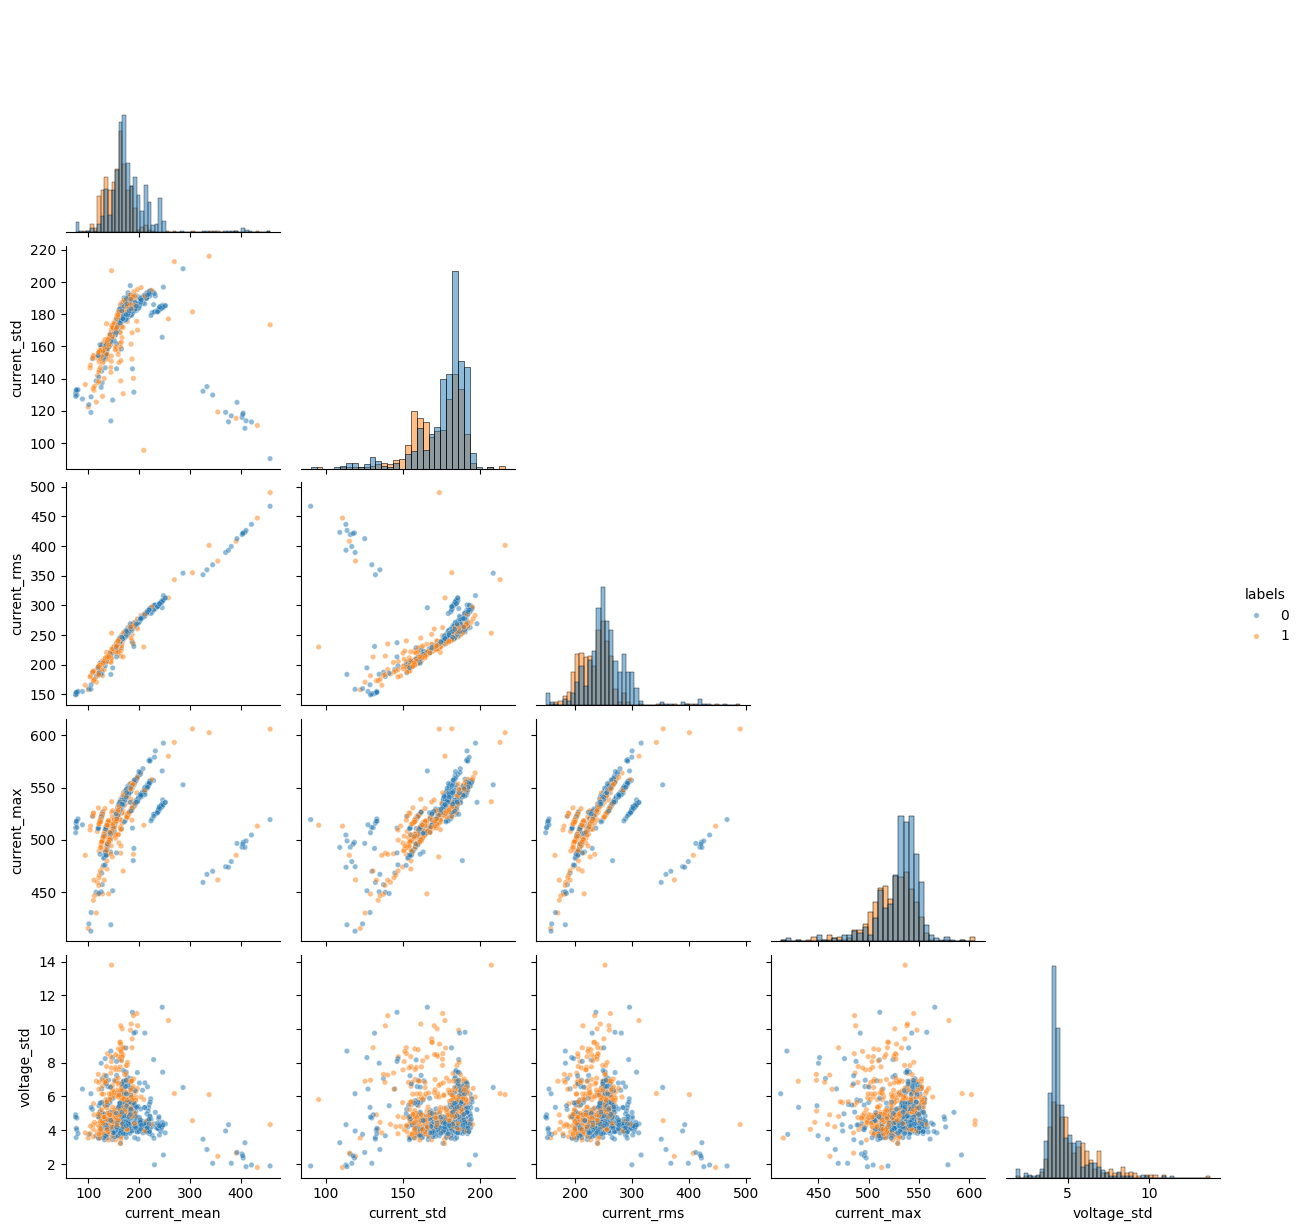

In [10]:

# Select features to visualize
selected_features = [
    "current_mean",
    "current_std",
    "current_rms",
    "current_max",
    "voltage_std"
]

# Include quality labels
plot_data = features[selected_features + ["labels"]].copy()

# Convert labels to categories
plot_data["labels"] = plot_data["labels"].astype(str)

# Create pairplot
sns.pairplot(
    plot_data,
    hue="labels",
    diag_kind="hist",
    corner=True,
    plot_kws={"alpha": 0.5, "s": 15}
)

plt.show()


## Exercise 3.4: Describe Your Feature Selection

Based on the pairplot visualization from Exercise 3.1, provide a detailed analysis of your feature selection:

1. Which features appear most effective at separating the quality classes?
2. Are there features that show strong correlation with each other? Would it make sense to remove any redundant features?
3. Explain the physical significance of your selected features in the context of welding quality.
4. If you were to select a subset of 5 most important features for classifying welding quality, which would you choose and why?
5. Discuss any patterns or insights you discovered in the data visualization that might help with building a classification model.


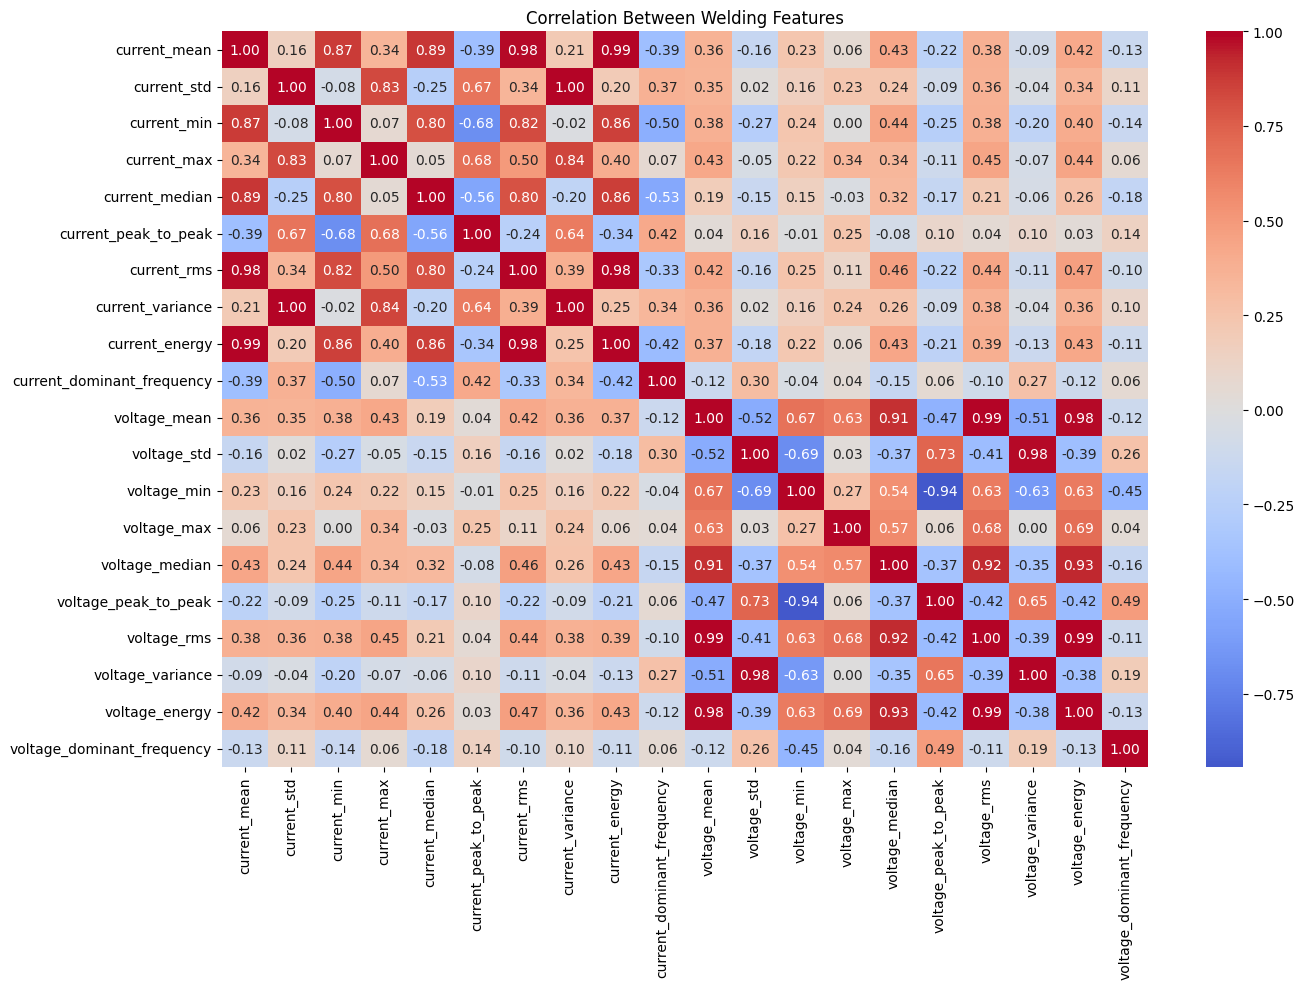

In [11]:
# Remove label column
X = features.drop(columns=["labels"])

# Calculate correlation
corr = X.corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Between Welding Features")
plt.tight_layout()
plt.show()


In [ ]:
### 1. Which features appear most effective at separating the quality classes?
Based on the pairplot visualization, the most promising features for distinguishing welding quality classes are:
- current_mean: The distributions of quality classes 0 and 1 show some differences, although considerable overlap exists.
- current_std: The histogram shows differences in the concentration of samples belonging to the two classes, making this feature potentially useful.
- current_rms: Shows a distribution similar to current_mean, with some differences between the quality classes.
- voltage_std: The distributions overlap substantially, but class 1 appears more represented in parts of the higher-variability range.
- current_max: Shows some variation between classes, particularly around extreme values, although its overall discriminative ability appears limited.
No single feature provides complete separation between classes 0 and 1. Therefore, combining multiple features is likely to improve classification performance.

### 2. Are there features that show strong correlation with each other? Would it make sense to remove redundant features?
The correlation heatmap reveals several strongly correlated feature pairs:
Feature pair - Pearson correlation 
current_mean – current_energy  0.99 
current_mean – current_rms  0.98 
current_std – current_variance  1.00 
current_rms – current_energy  0.98 
voltage_mean – voltage_rms  0.99 
voltage_rms – voltage_energy  0.99 
voltage_std – voltage_variance  0.98 
voltage_min – voltage_peak_to_peak  -0.94 

These correlations indicate that several features contain overlapping information.
For example, current_std and current_variance describe the same underlying property of current variability. Similarly, current_mean, current_rms, and current_energy all capture aspects of current magnitude.
Removing redundant features could reduce model complexity, improve interpretability, and help distance-based classifiers avoid giving excessive weight to highly correlated measurements.
However, feature removal should be validated against classification performance, because correlation alone does not determine predictive usefulness.

### 3. Explain the physical significance of your selected features in the context of welding quality.
The extracted features represent different electrical characteristics of the welding process.
- Mean current: Represents the average current supplied during welding. Current influences heat generation and can affect weld penetration and bonding.
- Current standard deviation: Measures fluctuations in current. Large variations may indicate unstable welding conditions.
- Current RMS: Represents the effective current magnitude and is related to resistive heating during welding.
- Maximum current: Captures peak current values. Excessive peaks may contribute to overheating or other welding defects.
- Voltage standard deviation: Measures voltage fluctuations, which may indicate changes in electrical contact conditions or process stability.

These features are physically meaningful because welding quality depends partly on electrical energy delivery and process stability.

### 4. If you were to select a subset of 5 most important features for classifying welding quality, which would you choose and why?
Based on the pairplot and correlation heatmap, I would initially select:
Selected feature | Reason 
current_mean | Represents average current and provides information about heat input 
current_std | Captures current variability and process stability 
current_max | Represents peak current and possible extreme operating conditions 
voltage_std | Captures voltage fluctuations and possible process instability 
voltage_peak_to_peak | Represents the voltage range and may capture abrupt electrical changes 

These five features represent different aspects of the welding signals, including average magnitude, variability, peak values, and voltage range.
I would avoid including current_rms alongside current_mean in this initial subset because their correlation is approximately 0.98.
Similarly, current_variance would be excluded because it is almost perfectly correlated with current_std.
The selected features are an initial, interpretable subset rather than a statistically confirmed ranking of the five best predictors.

### 5. Discuss any patterns or insights discovered in the visualization that might help with building a classification model.
Several important patterns can be identified:

Class overlap: The pairplot shows substantial overlap between quality classes 0 and 1. This suggests that simple linear decision boundaries may not be sufficient to distinguish all welding conditions.

Strong feature correlations: Multiple current and voltage features are highly correlated. Feature selection can help reduce redundancy before training.

Nonlinear relationships: The relationship between current_mean and current_std appears nonlinear, with a distinct group of observations at higher mean current and lower standard deviation. This suggests that nonlinear classification models may be useful.

Outliers: Some observations show unusually high current_mean, current_rms, or voltage_std values. These may represent unusual welding conditions and should be investigated rather than automatically removed.

Class distribution differences: Although the classes overlap, their concentrations differ in some regions of the feature space. Combining several features may improve discrimination.

Based on these observations, Random Forest, Gradient Boosting, and Support Vector Machines with nonlinear kernels would be reasonable models to evaluate.

Feature standardization should also be considered for scale-sensitive models, because the extracted features have different numerical ranges.